In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath('../..')
sys.path.append(PROJECT_ROOT)
PROJECT_ROOT = os.path.abspath('../../stabilizer_sim')
sys.path.append(PROJECT_ROOT)
import stabilizer_sim.codes.three_bit_repitition as tr
import stabilizer_sim.codes.nine_bit_repitition as nr
import stabilizer_sim.codes.toric as t

In [ ]:
er = {}
# TODO: check that this is rihgt
three_code = tr.ThreeQubitRepititionCode(seed=42, verbose=False)
for prob in range(1, 2):
    px = prob/100
    res = three_code.run(
        rounds=20,
        shots=1,
        px=px,
        pm=0.00
    )
    er[px] = res

In [ ]:
theory = [(3*(p/100)**2) - (2*(p/100)**3) for p in range(1, 50)]
plt.figure()
plt.plot(er.keys(), er.values(), label='Simulation')
plt.plot(er.keys(), theory, label='Theory')
plt.xlabel('X error probability')
plt.ylabel('Logical error rate')
plt.legend()
plt.show()

In [ ]:
er = {}
m_error_res = 10
p_error_res = 50
three_code = tr.ThreeQubitRepititionCode(seed=42, verbose=False)
for m_error in range(m_error_res):
    pm = m_error/(20 * m_error_res)
    erx = {}
    for p_error in range(1, p_error_res):
        px = p_error/(2 * p_error_res)
        res = three_code.run(
            rounds=20,
            shots=1000,
            px=px,
            pm=pm
        )

        erx[px] = res
        
    er[pm] = erx

In [ ]:
print(er)
plt.figure()
for k, v in er.items():
    plt.plot(v.keys(), v.values(), label=k)
    plt.xlabel('Data error prob')
    # both logical error and non-codestates
    plt.ylabel('Logical Error prob')
    plt.title('Logical errors for range of data and measurement errors (20 rounds, 1000 shots)')
plt.legend()

# plt.show()

In [ ]:
plt.savefig('../../figs/rep3_px.png')

In [ ]:
dist = 9
res = {}
pms = [1e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 3e-2, 6e-2, 1e-1]
# pms=[5e-4]
pp = [1e-5, 3e-5, 5e-5, 8e-5, 1e-4, 3e-4,  5e-4, 8e-4, 1e-3, 3e-3,  5e-3, 8e-3, 1e-2, 3e-2, 5e-2, 8e-2, 1e-1, 1.5e-1, 2e-1]
res = {
    'no_error': {},
    'logical': {},
    'outside': {}
}
for pm in pms:
    resp = {
        'no_error': {},
        'logical': {},
        'outside': {}
    }
    for p in pp:
        code = t.ToricCode(dist=dist, verbose=False, seed=None)
        error_rate = code.run(
            shots=2000,
            rounds=dist,
            px=p,
            py=p,
            pz=p,
            pm=pm
        )
        for k, v in error_rate.items():
                resp[k][p] = v
    for k, v in resp.items(): 
        res[k][pm] = v
print(res)

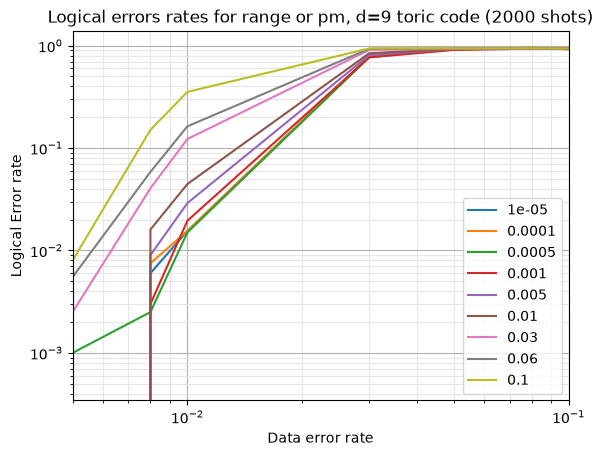

In [45]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res['logical'].items():
    plt.loglog(v.keys(), v.values(), label=k)
plt.xlabel('Data error rate')
plt.xlim(5e-3, 1e-1)
# plt.ylim(1e-2, 1e0)
plt.ylabel('Logical Error rate')
plt.title('Logical errors rates for range or pm, d=9 toric code (2000 shots)')
plt.savefig('../../figs/toric_d9_depol.png')
plt.legend()
plt.show()

In [ ]:
# Physical noise vs distance for constant measurement error
res1 = {}
dists = [3, 5, 7, 9, 11, 13]
pms=[0]
pp = [1e-5, 3e-5, 5e-5, 8e-5, 1e-4, 3e-4, 5e-4, 8e-4, 1e-3, 3e-3,  5e-3, 8e-3, 1e-2, 3e-2, 5e-2, 8e-2, 1e-1, 1.5e-1]
for dist in dists:
    resp = {}
    for p in pp:
        code = t.ToricCode(dist=dist, verbose=False, seed=None)
        error_rate = code.run(
            shots=2000,
            rounds=20,
            px=p,
            py=p,
            pz=p,
            pm=5e-4
        )
        resp[p] = error_rate
    res1[dist] = resp
print(res1)

In [ ]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res1.items():
    plt.loglog(v.keys(), v.values(), label=f'd={k}')
plt.xlabel('Data error rate')
# both logical error and non-codestates
plt.ylabel('Logical Error rate')
plt.title('Logical errors rates for toric code (20 rounds, 2000 shots, pm=5e-4)')
plt.legend()
plt.savefig('../../figs/toric_d_depol_pm5e-4.png')
plt.show()

In [ ]:
# Logical error/outside space for constant measurement error and
# Physical noise vs distance for constant measurement error
res3 = {
    'no_error': {},
    'logical': {},
    'outside': {}
}
dists = [3, 5, 7, 9, 11, 13]
pms=[0]
pp = [1e-5, 3e-5, 5e-5, 8e-5, 1e-4, 3e-4, 5e-4, 8e-4, 1e-3, 3e-3, 5e-3, 8e-3, 1e-2, 3e-2, 5e-2, 8e-2, 1e-1, 1.5e-1, 2e-1, 2.4e-1]# 3e-1, 3.5e-1, 4e-1]
for dist in dists:
    resp = {
        'no_error': {},
        'logical': {},
        'outside': {}
    }
    for p in pp:
        code = t.ToricCode(dist=dist, verbose=False, seed=None)
        error_rate = code.run(
            shots=6000,
            rounds=dist,
            px=p,
            py=p,
            pz=p,
            pm=5e-4
        )
        
        for k, v in error_rate.items():
            resp[k][p] = v
    for k, v in resp.items(): 
        res3[k][dist] = v
print(res3)

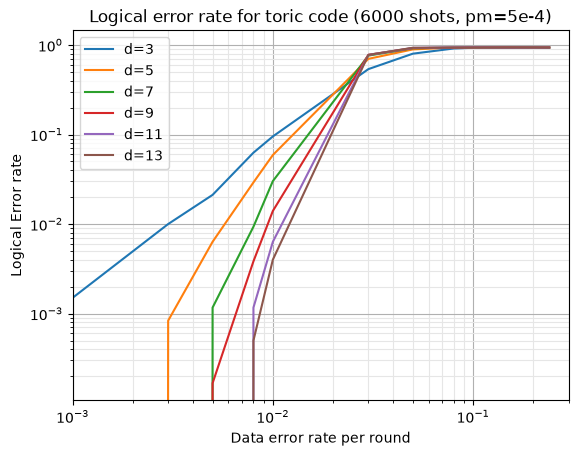

In [ ]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res3['logical'].items():
    plt.loglog(v.keys(), [x for x in v.values()], label=f'd={k}')
plt.xlabel('Data error rate per round')
plt.xlim(1e-3, 3e-1)
# both logical error and non-codestates
plt.ylabel('Logical Error rate')
plt.title('Logical error rate for toric code (6000 shots, pm=5e-4)')
plt.legend()
plt.savefig('../../figs/toric_d_depol_logic_error.png')
plt.show()

/home/andrew/Documents/github/qec-decoder-benchmark/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  fig.canvas.print_figure(bytes_io, **kw)


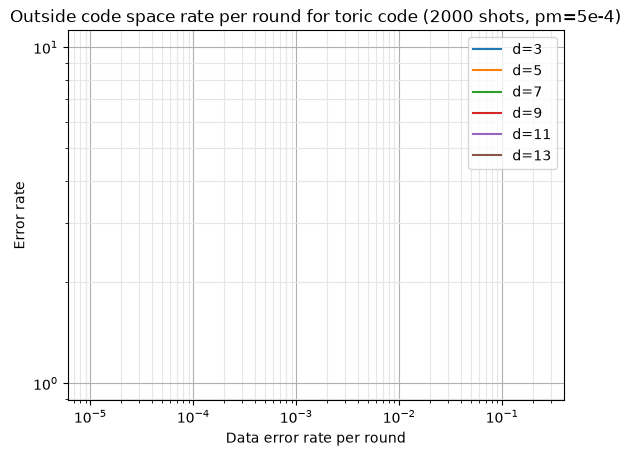

In [18]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res3['outside'].items():
    plt.loglog(v.keys(), [x / k for x in v.values()], label=f'd={k}')
plt.xlabel('Data error rate per round')
# both logical error and non-codestates
plt.ylabel('Error rate')
plt.title('Outside code space rate per round for toric code (2000 shots, pm=5e-4)')
plt.legend()
# plt.savefig('../../figs/toric_d_depol_outside_code.png')
plt.show()

In [ ]:
combined = {
    dist: {p: res3['logical'][dist][p] + res3['outside'][dist][p]
           for p in res3['logical'][dist]}
    for dist in res3['logical']
}
print(combined)
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in combined.items():
    plt.loglog(v.keys(), [x for x in v.values()], label=f'd={k}')
plt.xlabel('Data error rate per round')
# both logical error and non-codestates
plt.ylabel('Decoder failure rate')
plt.title('Total decoder failure rate (6000 shots, pm=5e-4)')
plt.legend()
plt.savefig('../../figs/toric_d_depol_combined.png')
plt.show()